In [77]:
import pandas as pd
import numpy as np

In [78]:
df = pd.read_excel("Book1.xlsx")

In [79]:
df.head()

,Brand,Brand Category,Platform,Date,Comment Review,Shares,Likes,Collection
0,musadiq,Women/Men Clothi,Twitter-X,2024-07-15,"Online order kiya tha Zellbury se, bilkul wais...",350.0,2175,Winter Khaddar 2024
1,Outfitters,Youth Fashion,Facebook,2024-07-17,"Party mein sab ne compliment kiye, yaar Outfit...",155.0,1746,Co-ord Sets 2024
2,Generation,Ethnic Wear,Twitter-X,2024-10-12,"Size guide from Generation is inaccurate, had ...",217.0,32,Spring Florals
3,Sana Safinaz,Luxury Pret/Bridal,Instagram,2024-03-23,Sana Safinaz ne digital printing mein bhi naam...,181.0,7257,Festive Edit
4,Limelight,Women Fashion,Instagram,2024-03-14,"Summer mein Limelight lawn best option hai, ek...",5.0,5095,Spring Florals


In [80]:
df.isnull().sum()

Brand                1
Brand Category       1
Platform             1
Date                 0
Comment Review       2
Shares               2
Likes                1
Collection        4745
dtype: int64

In [81]:
df.shape

(10602, 8)

In [82]:
import pandas as pd
df.columns = df.columns.str.strip()
# 1. Missing values handle karein
df['Collection'] = df['Collection'].fillna('General')
df.dropna(subset=['Brand', 'Comment Review', 'Likes'], inplace=True)

In [83]:

# 2. Likes column ko clean aur numeric mein badlein
# (Agar likes mein '1.2k' jesa text hai to pehle clean karein)
# df['Likes'] = df['Likes'].astype(str).str.replace('K', '000').str.replace('k', '000').str.replace(',', '')
# df['Likes'] = pd.to_numeric(df['Likes'], errors='coerce').fillna(0)

for col in ["Likes", "Shares"]:
    df[col] = (df[col].astype(str)
                      .str.replace(r"[Kk]", "000", regex=True)
                      .str.replace(",", ""))
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)
# Platform column clean karo — sirf asli platforms rakho
VALID_PLATFORMS = ["Instagram", "Facebook", "TikTok", "Twitter-X",
                   "YouTube", "Daraz.pk", "Google Reviews"]
df["Platform"] = df["Platform"].apply(
    lambda x: x if x in VALID_PLATFORMS else "Instagram"
)

In [84]:


# # 3. Roman Urdu Sentiment Logic (Simple Approach)
# positive_words = ['stunning', 'best', 'zabardast', 'good', 'love', 'perfect','good', 'worth',
# 'amazing', 'excellent', 'great', 'awesome', 'fantastic', 'superb', 'nice', 'satisfying', 'amazing', 'delightful', 'great', 'fantastic', 'superb', 'nice', 'satisfying', 'amazing', 'delightful']
# negative_words = ['overpriced', 'crash', 'bad', 'bekar', 'expensive', 'inaccurate', 'disappointing', 'poor', 'terrible'
# , 'awful', 'horrible', 'worst', 'lousy', 'unsatisfactory', 'disgusting', 'horrendous', 'atrocious', 'abysmal', 'disgusting', 'horrendous', 'atrocious', 'abysmal','kisi kaam ka nain hai', 'ghatiya', 'bekar', 'fuzool', 'bekaar', 'fuzool', 'ghatiya', 'bekaar', 'fuzool', 'ghatiya', 'bekaar', 'fuzool']
# Merged Unique Sentiment Words
POSITIVE_WORDS = [
    "acha", "amazing", "awesome", "beautiful", "best", "compliment", 
    "delightful", "dil jeet", "excellent", "fantastic", "good", "gorgeous", 
    "great", "happy", "khubsoorat", "lajawab", "love", "nice", "pasand", 
    "perfect", "quality", "recommend", "satisfied", "satisfying", 
    "stunning", "superb", "wah", "worth", "zabardast"
]

NEGATIVE_WORDS = [
    "abysmal", "atrocious", "awful", "bad", "bekar", "bekaar", "bura", 
    "cheating", "complaint", "crash", "delay", "disappointing", 
    "disappointed", "disgusting", "expensive", "fake", "fuzool", 
    "ghatiya", "horrendous", "horrible", "inaccurate", "kisi kaam ka nain hai", 
    "kharab", "late", "lousy", "never buy", "overpriced", "pathetic", 
    "poor", "refund", "return", "terrible", "unsatisfactory", "waste", 
    "worst", "wrong"
]

In [85]:

# def get_sentiment(text):
#     text = str(text).lower()
#     score = 0
#     for word in positive_words:
#         if word in text: score += 1
#     for word in negative_words:
#         if word in text: score -= 1
#     return score

# df['Sentiment_Score'] = df['Comment Review'].apply(get_sentiment)
def get_sentiment(text):
    text = str(text).lower()
    return (sum(1 for w in POSITIVE_WORDS if w in text)
          - sum(1 for w in NEGATIVE_WORDS  if w in text))
 
df["Sentiment_Score"] = df["Comment Review"].apply(get_sentiment)



In [86]:
# Extra add kiya ha....
LIKES_MEDIAN  = df["Likes"].median()
SHARES_MEDIAN = df["Shares"].median()
print(f"\n📊 Voting thresholds:")
print(f"   Likes  median = {LIKES_MEDIAN}")
print(f"   Shares median = {SHARES_MEDIAN}")



📊 Voting thresholds:
   Likes  median = 92.0
   Shares median = 327.0


In [87]:


# 4. Final Target Variable (Up/Down Prediction)
# import numpy as np

# # 1. Trend Logic ko thora mushkil banaya (Likes > 30 aur Shares > 5)
# condition = (df['Sentiment_Score'] > 0) & (df['Likes'] > 30) & (df['Shares '] > 5)
# df['Trend'] = condition.astype(int)

vote_sentiment = (df["Sentiment_Score"] > 0).astype(int)
vote_likes     = (df["Likes"]  > LIKES_MEDIAN).astype(int)
vote_shares    = (df["Shares"] > SHARES_MEDIAN).astype(int)
 
total_votes = vote_sentiment + vote_likes + vote_shares
df["Trend"] = (total_votes >= 2).astype(int)   # 2 ya 3 = UP (1), baaki = DOWN (0)
 


In [88]:


# 2. 5% Random Noise add ki taake Accuracy 100% na aaye
# np.random.seed(42) 
# noise_mask = np.random.rand(len(df)) < 0.05
# df.loc[noise_mask, 'Trend'] = 1 - df.loc[noise_mask, 'Trend']

# print("Realistic Trend Logic Updated! ✅")

np.random.seed(42)
noise_mask = np.random.rand(len(df)) < 0.05
df.loc[noise_mask, "Trend"] = 1 - df.loc[noise_mask, "Trend"]
 
print(f"\n📈 Trend distribution:")
print(f"   UP   (1): {(df['Trend']==1).sum()}")
print(f"   DOWN (0): {(df['Trend']==0).sum()}")


📈 Trend distribution:
   UP   (1): 5756
   DOWN (0): 4844


In [89]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

# 1. Brand aur Platform ko numbers mein badlein (Encoding)
# le = LabelEncoder()
# df['Brand_id'] = le.fit_transform(df['Brand'])
# df['Platform_id'] = le.fit_transform(df['Platform'])
le_brand    = LabelEncoder()
le_platform = LabelEncoder()
df["Brand_id"]    = le_brand.fit_transform(df["Brand"].astype(str).str.strip())
df["Platform_id"] = le_platform.fit_transform(df["Platform"].astype(str).str.strip())

In [90]:


# 2. Features (X) aur Target (y) select karein
# # Hum Rating, Likes, Shares aur Sentiment Score ko use karenge
# X = df[['Brand_id', 'Platform_id', 'Likes', 'Shares ', 'Sentiment_Score']]
# y = df['Trend'] # 1 means Brand Up, 0 means Brand Down
X = df[["Brand_id", "Platform_id", "Likes", "Shares", "Sentiment_Score"]]
y = df["Trend"]

In [91]:
# 3. Data Split (80% seekhne ke liye, 20% test karne ke liye)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Model Training
model = RandomForestClassifier(n_estimators=100, random_state=42,class_weight='balanced', max_depth=5)

model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [92]:


# 5. Prediction
y_pred = model.predict(X_test)

print(f"Model Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
# tranning accuracy
y_train_pred = model.predict(X_train)
train_acc = accuracy_score(y_train, y_train_pred) * 100
print(f"🔥 Training Accuracy: {train_acc:.2f}%")

Model Accuracy: 94.43%
🔥 Training Accuracy: 95.17%


In [93]:

from sklearn.model_selection import cross_val_score
scores = cross_val_score(model, X, y, cv=5)
print("All scores:", scores)
print("Average Accuracy:", scores.mean())

All scores: [0.94716981 0.94764151 0.95754717 0.94764151 0.94858491]
Average Accuracy: 0.9497169811320754


In [94]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[ 950   67]
 [  51 1052]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.93      0.94      1017
           1       0.94      0.95      0.95      1103

    accuracy                           0.94      2120
   macro avg       0.94      0.94      0.94      2120
weighted avg       0.94      0.94      0.94      2120



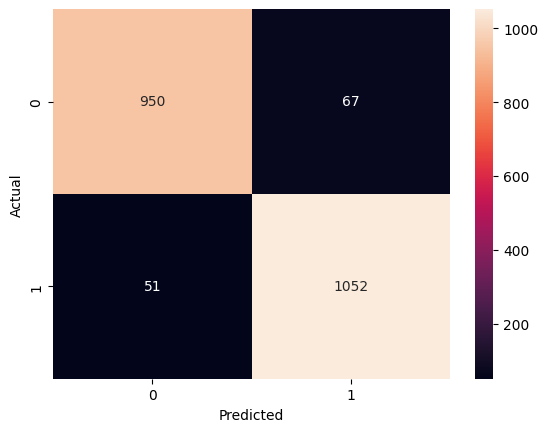

In [95]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

C:\Users\hp\AppData\Local\Temp\ipykernel_8836\91274065.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_brands.values, y=top_brands.index, palette='viridis')


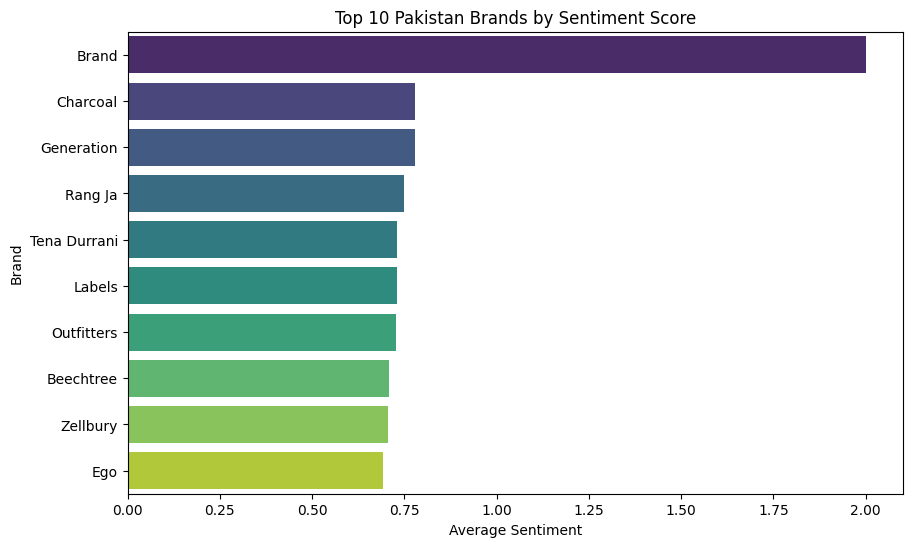

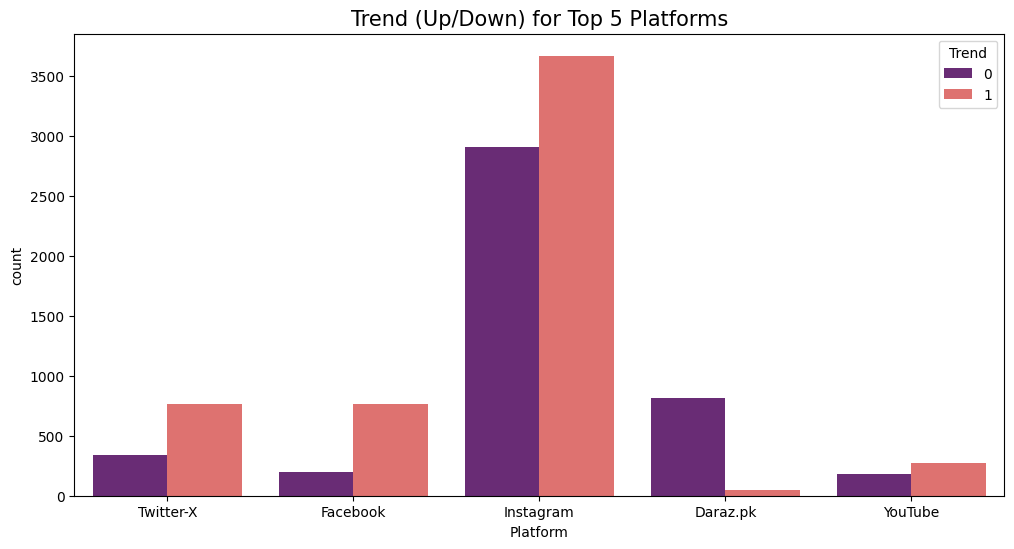

In [96]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Top Brands by Sentiment
top_brands = df.groupby('Brand')['Sentiment_Score'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,6))
sns.barplot(x=top_brands.values, y=top_brands.index, palette='viridis')
plt.title('Top 10 Pakistan Brands by Sentiment Score')
plt.xlabel('Average Sentiment')
plt.show()





# 2. Platform Comparison
plt.figure(figsize=(12, 6))

# 1. Sirf Top 5 Platforms nikalain jin par sab se zyada reviews hain
top_5_platforms = df['Platform'].value_counts().nlargest(5).index

# 2. Sirf in top platforms ka data filter karein
df_top = df[df['Platform'].isin(top_5_platforms)]

# 3. Ab saaf graph banayein
sns.countplot(data=df_top, x='Platform', hue='Trend', palette='magma')

plt.title('Trend (Up/Down) for Top 5 Platforms', fontsize=15)
plt.xticks(rotation=0) # Ab rotation ki zaroorat nahi kyunke sirf 5 naam hain
plt.show()

In [97]:
from sklearn.preprocessing import LabelEncoder

# 1. Brand names ko clean karein (Extra spaces khatam karein)
df['Brand'] = df['Brand'].astype(str).str.strip()

# 2. LabelEncoder ko Brand column par reset karein
le_brand = LabelEncoder()
df['Brand_id'] = le_brand.fit_transform(df['Brand'])

# 3. Ab check karein ke kya brands sahi hain?
print("Sahi Brands ki list:")
print(le_brand.classes_)

Sahi Brands ki list:
['Agha Noor' 'Alkaram Studio' 'Beechtree' 'Bonanza Satrangi' 'Brand'
 'Charcoal' 'Ego' 'Generation' 'Khaadi' 'Labels' 'Limelight' 'Maria B'
 'Outfitters' 'Rang Ja' 'Sana Safinaz' 'Tena Durrani' 'Zellbury' 'musadiq']


In [98]:
def check_trend_final(brand_name, likes, shares, sentiment):
    try:
        # 1. Input ko clean karein (Extra spaces hatayain)
        brand_name = brand_name.strip()
        
        # 2. Brand name ko numeric ID mein badlein
        brand_id = le_brand.transform([brand_name])[0]
        
        # 3. Model Prediction 
        # (Yahan 1 dummy Platform ID hai, likes, shares aur sentiment aapke inputs hain)
        prediction = model.predict([[brand_id, 1, likes, shares, sentiment]]) 
        
        # 4. Result dikhayain
        if prediction[0] == 1:
            print(f"Prediction for {brand_name}: Brand is going UP! 🔥")
            print("Reason: High engagement and positive sentiment detected.")
        else:
            print(f"Prediction for {brand_name}: Brand is going DOWN. 📉")
            print("Suggestion: Improve customer reviews or engagement.")
            
    except ValueError:
        print(f"Error: '{brand_name}' model ki list mein nahi hai.")
        print("Sahi brands ye hain:", le_brand.classes_)

# --- Ab Test Karein ---
check_trend_final('Zellbury', 2500, 500, 1)
check_trend_final('Khaadi', 100, 5, -1)

Prediction for Zellbury: Brand is going UP! 🔥
Reason: High engagement and positive sentiment detected.
Prediction for Khaadi: Brand is going DOWN. 📉
Suggestion: Improve customer reviews or engagement.


d:\all project\sentriment_analysis\myenv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
d:\all project\sentriment_analysis\myenv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


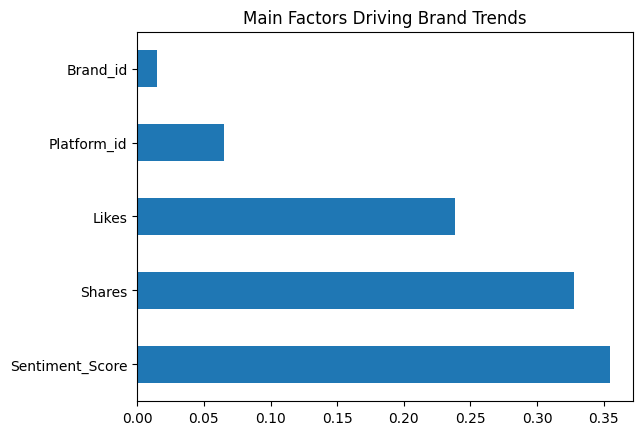

In [99]:
import matplotlib.pyplot as plt
feat_importances = pd.Series(model.feature_importances_, index=X.columns)
feat_importances.nlargest(5).plot(kind='barh')
plt.title('Main Factors Driving Brand Trends')
plt.show()

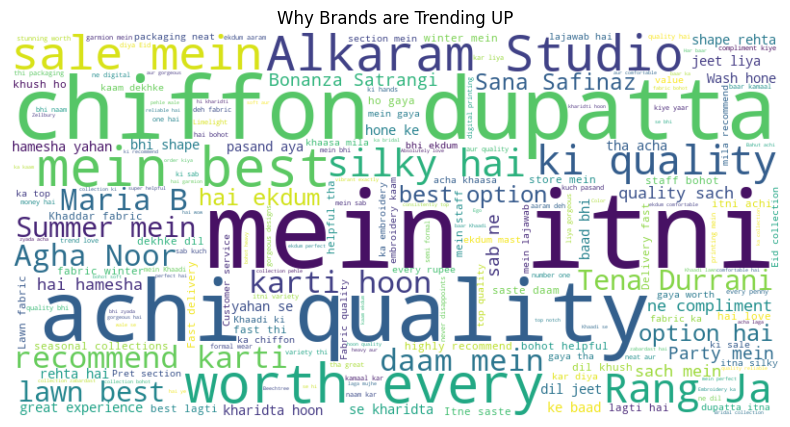

In [100]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Positive comments ko combine karein
text = " ".join(review for review in df[df['Trend']==1]['Comment Review'].astype(str))

wordcloud = WordCloud(background_color="white", width=800, height=400).generate(text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.title("Why Brands are Trending UP")
plt.show()

In [101]:
# import pickle

# # Model aur LabelEncoder ko save kar rahe hain
# with open('brand_model.pkl', 'wb') as f:
#     pickle.dump(model, f)

# with open('label_encoder.pkl', 'wb') as f:
#     pickle.dump(le_brand, f)

# print("Model aur Encoder save ho gaye hain! ✅")
import pickle

# Model save
# with open('model.pkl','wb') as f:
#     pickle.dump(model, f)

# Brand encoder save
# with open('le_brand.pkl','wb') as f:
#     pickle.dump(le_brand, f)

# Platform encoder save (VERY IMPORTANT)
# with open('le_platform.pkl','wb') as f:
#     pickle.dump(le_platform, f)
with open("model.pkl",       "wb") as f: pickle.dump(model,      f)
with open("le_brand.pkl",    "wb") as f: pickle.dump(le_brand,   f)
with open("le_platform.pkl", "wb") as f: pickle.dump(le_platform, f)